# Road pothole segmentation — SegFormer MiT-B5, 5-fold CV, flip TTA

Notebook from the ARA ITS 2026 data science competition (team Analyx). The task is binary segmentation: mark the pothole pixels in each road photo. Training data: 498 images with masks; test: 295 images. The outputs below come from the competition run on a Kaggle T4.

## 1. Setup
Extra packages on top of Kaggle's preinstalled PyTorch.

In [1]:
# Cukup install library tambahannya saja tanpa menyentuh Torch bawaan
!pip install -q segmentation-models-pytorch --no-deps
!pip install -q pretrainedmodels efficientnet-pytorch timm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 8.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 kB 2.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done


In [15]:
import os, cv2, random, numpy as np, pandas as pd
from glob import glob
from tqdm.auto import tqdm
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
import torch.amp as amp
import skimage.morphology as morph
from sklearn.model_selection import KFold
import gc
import matplotlib.pyplot as plt

## 2. Configuration and file lists
Images and masks are paired by sorted filename (`train_001.jpg` ↔ `mask_001.png`). Set `ARA_DATA_DIR` to run outside Kaggle.

In [28]:
# ==============================================================================
# CONFIGURATION
# ==============================================================================
CFG = {
    'device': 'cuda' if torch.cuda.is_available() else 'cpu',
    'img_size': 512,
    'batch_size': 4, # Sesuaikan dengan memori GPU (B5 cukup berat)
    'lr': 2e-4,
    'epochs': 30,
    'n_folds': 5,
    'seed': 42,
    'encoder': 'mit_b5',
    'patience': 10
}

# Folder hasil ekstrak dataset lomba (berisi train/ dan test/).
# Default = lokasi dataset saat dijalankan di Kaggle; ganti lewat env var ARA_DATA_DIR.
DATA_DIR   = os.environ.get('ARA_DATA_DIR', '/kaggle/input/dataset-ara/dataset/dataset')
TRAIN_ROOT = f'{DATA_DIR}/train'
TEST_ROOT  = f'{DATA_DIR}/test/images'

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything(CFG['seed'])

train_imgs = sorted(glob(f'{TRAIN_ROOT}/images/*'))
train_masks = sorted(glob(f'{TRAIN_ROOT}/mask/*'))
test_imgs = sorted(glob(f'{TEST_ROOT}/*'))

assert len(train_imgs) == len(train_masks) > 0, f'Dataset tidak ditemukan di {DATA_DIR}'
print(f'train: {len(train_imgs)} citra + mask | test: {len(test_imgs)} citra')

## 3. Dataset and augmentation
Masks are binarised at 127. Training uses random crops, flips, small shifts/rotations and brightness changes; validation only resizes to 512×512 and normalises.

In [29]:
class PotholeDataset(Dataset):
    def __init__(self, imgs, masks=None, aug=None):
        self.imgs, self.masks, self.aug = imgs, masks, aug

    def __len__(self): return len(self.imgs)

    def __getitem__(self, idx):
        img = cv2.imread(self.imgs[idx])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        if self.masks is not None:
            mask = cv2.imread(self.masks[idx], 0)
            mask = (mask > 127).astype('float32')
        else:
            mask = np.zeros(img.shape[:2], dtype='float32')

        if self.aug:
            augmented = self.aug(image=img, mask=mask)
            img, mask = augmented['image'], augmented['mask']

        return img, mask.unsqueeze(0)

# Augmentasi Training
train_aug = A.Compose([
    # Fungsi ini meminta 'size' (tuple)
    A.RandomResizedCrop(
        size=(CFG['img_size'], CFG['img_size']), 
        scale=(0.7, 1.0), 
        p=1.0
    ),
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.1, rotate_limit=15, p=0.5),
    A.RandomBrightnessContrast(p=0.3),
    A.Normalize(), 
    ToTensorV2()
])

# Augmentasi Validasi
val_aug = A.Compose([
    # Fungsi ini (berdasarkan error Anda sebelumnya) meminta 'height' & 'width'
    A.Resize(
        height=CFG['img_size'], 
        width=CFG['img_size']
    ),
    A.Normalize(), 
    ToTensorV2()
])

## 4. Model and loss
SegFormer with an ImageNet-pretrained MiT-B5 encoder. Loss = 0.7 × Tversky (α=0.3, β=0.7, so missed pothole pixels cost more than false alarms) + 0.3 × BCE.

In [30]:
def build_model(encoder):
    return smp.Segformer(
        encoder_name=encoder,
        encoder_weights='imagenet',
        in_channels=3,
        classes=1
    ).to(CFG['device'])

# Tversky Loss sangat bagus untuk menangani imbalance data (pothole kecil)
tversky_loss = smp.losses.TverskyLoss(mode='binary', alpha=0.3, beta=0.7)
bce_loss = nn.BCEWithLogitsLoss()

def loss_fn(preds, targets):
    return 0.7 * tversky_loss(preds, targets) + 0.3 * bce_loss(preds, targets)

## 5. 5-fold training
One model per fold. AdamW + cosine schedule, mixed precision, checkpoint on best validation Dice, early stop after 10 epochs without improvement. Validation Dice is computed per batch at a 0.5 threshold, without TTA or post-processing.

In [33]:
import matplotlib.pyplot as plt

kf = KFold(n_splits=CFG['n_folds'], shuffle=True, random_state=CFG['seed'])

all_histories = []

for fold, (tr_idx, va_idx) in enumerate(kf.split(train_imgs)):
    print(f"\n{'='*20} Fold {fold+1} {'='*20}")
    
    # 1. Siapkan Data
    tr_imgs = [train_imgs[i] for i in tr_idx]; tr_masks = [train_masks[i] for i in tr_idx]
    va_imgs = [train_imgs[i] for i in va_idx]; va_masks = [train_masks[i] for i in va_idx]

    train_loader = DataLoader(PotholeDataset(tr_imgs, tr_masks, train_aug), batch_size=CFG['batch_size'], shuffle=True, num_workers=2, pin_memory=True)
    val_loader = DataLoader(PotholeDataset(va_imgs, va_masks, val_aug), batch_size=CFG['batch_size'], shuffle=False, num_workers=2)

    # 2. Inisialisasi Model & Optimizer
    model = build_model(CFG['encoder']) 
    
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG['lr'])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG['epochs'])
    scaler = amp.GradScaler('cuda')

    fold_history = {'train_loss': [], 'val_loss': [], 'val_dice': []}
    
    # PERUBAHAN DISINI: Gunakan best_dice untuk menimbang performa
    best_dice = 0.0 
    early_stop_counter = 0

    # 3. Mulai Training Loop
    for epoch in range(CFG['epochs']):
        # --- TRAINING ---
        model.train()
        train_loss = 0
        for imgs, masks in tqdm(train_loader, desc=f"Epoch {epoch+1}", leave=False):
            imgs, masks = imgs.to(CFG['device']), masks.to(CFG['device'])
            optimizer.zero_grad()
            with amp.autocast('cuda'):
                preds = model(imgs)
                loss = loss_fn(preds, masks)
            
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            train_loss += loss.item()
            
        avg_train_loss = train_loss / len(train_loader)

        # --- VALIDATION ---
        model.eval()
        val_loss = 0
        val_dice = 0
        with torch.no_grad():
            for imgs, masks in val_loader:
                imgs, masks = imgs.to(CFG['device']), masks.to(CFG['device'])
                
                preds = model(imgs)
                val_loss += loss_fn(preds, masks).item()
                
                preds = torch.sigmoid(preds)
                preds = (preds > 0.5).float()
                
                intersection = (preds * masks).sum()
                dice = (2. * intersection) / (preds.sum() + masks.sum() + 1e-6)
                val_dice += dice.item()
        
        avg_val_loss = val_loss / len(val_loader)
        avg_val_dice = val_dice / len(val_loader)
        
        # Simpan ke history
        fold_history['train_loss'].append(avg_train_loss)
        fold_history['val_loss'].append(avg_val_loss)
        fold_history['val_dice'].append(avg_val_dice)

        scheduler.step()
        print(f"Epoch {epoch+1} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Dice: {avg_val_dice:.4f}")
        
        # --- LOGIKA EARLY STOPPING & MODEL SAVING BERDASARKAN DICE ---
        # Kita mencari Dice Score TERTINGGI
        if avg_val_dice > best_dice:
            best_dice = avg_val_dice
            torch.save(model.state_dict(), f'best_model_fold{fold}.pth')
            print(f"  ✅ Saved Model (New Best Dice: {best_dice:.4f})")
            early_stop_counter = 0 # Reset counter karena performa meningkat
        else:
            early_stop_counter += 1
            print(f"  ⚠️ Dice did not improve for {early_stop_counter} epoch(s)")

        if early_stop_counter >= CFG['patience']:
            print(f"  🛑 Early stopping triggered at epoch {epoch+1}. Moving to next fold.")
            break

    all_histories.append(fold_history)
    del model; gc.collect(); torch.cuda.empty_cache()


==================== Fold 1 ====================


Epoch 1:   0%|          | 0/100 [00:00<?, ?it/s]

Epoch 1 | Train Loss: 0.3930 | Val Loss: 0.3025 | Val Dice: 0.7116
  ✅ Saved Model (New Best Dice: 0.7116)


Epoch 2:   0%|          | 0/100 [00:00<?, ?it/s]

Epoch 2 | Train Loss: 0.2652 | Val Loss: 0.2345 | Val Dice: 0.7514
  ✅ Saved Model (New Best Dice: 0.7514)


...

Epoch 25 | Train Loss: 0.0502 | Val Loss: 0.1782 | Val Dice: 0.8257
  ⚠️ Dice did not improve for 8 epoch(s)


Epoch 26:   0%|          | 0/100 [00:00<?, ?it/s]

Epoch 26 | Train Loss: 0.0490 | Val Loss: 0.1811 | Val Dice: 0.8249
  ⚠️ Dice did not improve for 9 epoch(s)


Epoch 27:   0%|          | 0/100 [00:00<?, ?it/s]

Epoch 27 | Train Loss: 0.0477 | Val Loss: 0.1833 | Val Dice: 0.8241
  ⚠️ Dice did not improve for 10 epoch(s)
  🛑 Early stopping triggered at epoch 27. Moving to next fold.


## 6. Training curves
Validation loss and Dice per fold; stars mark the saved epoch.

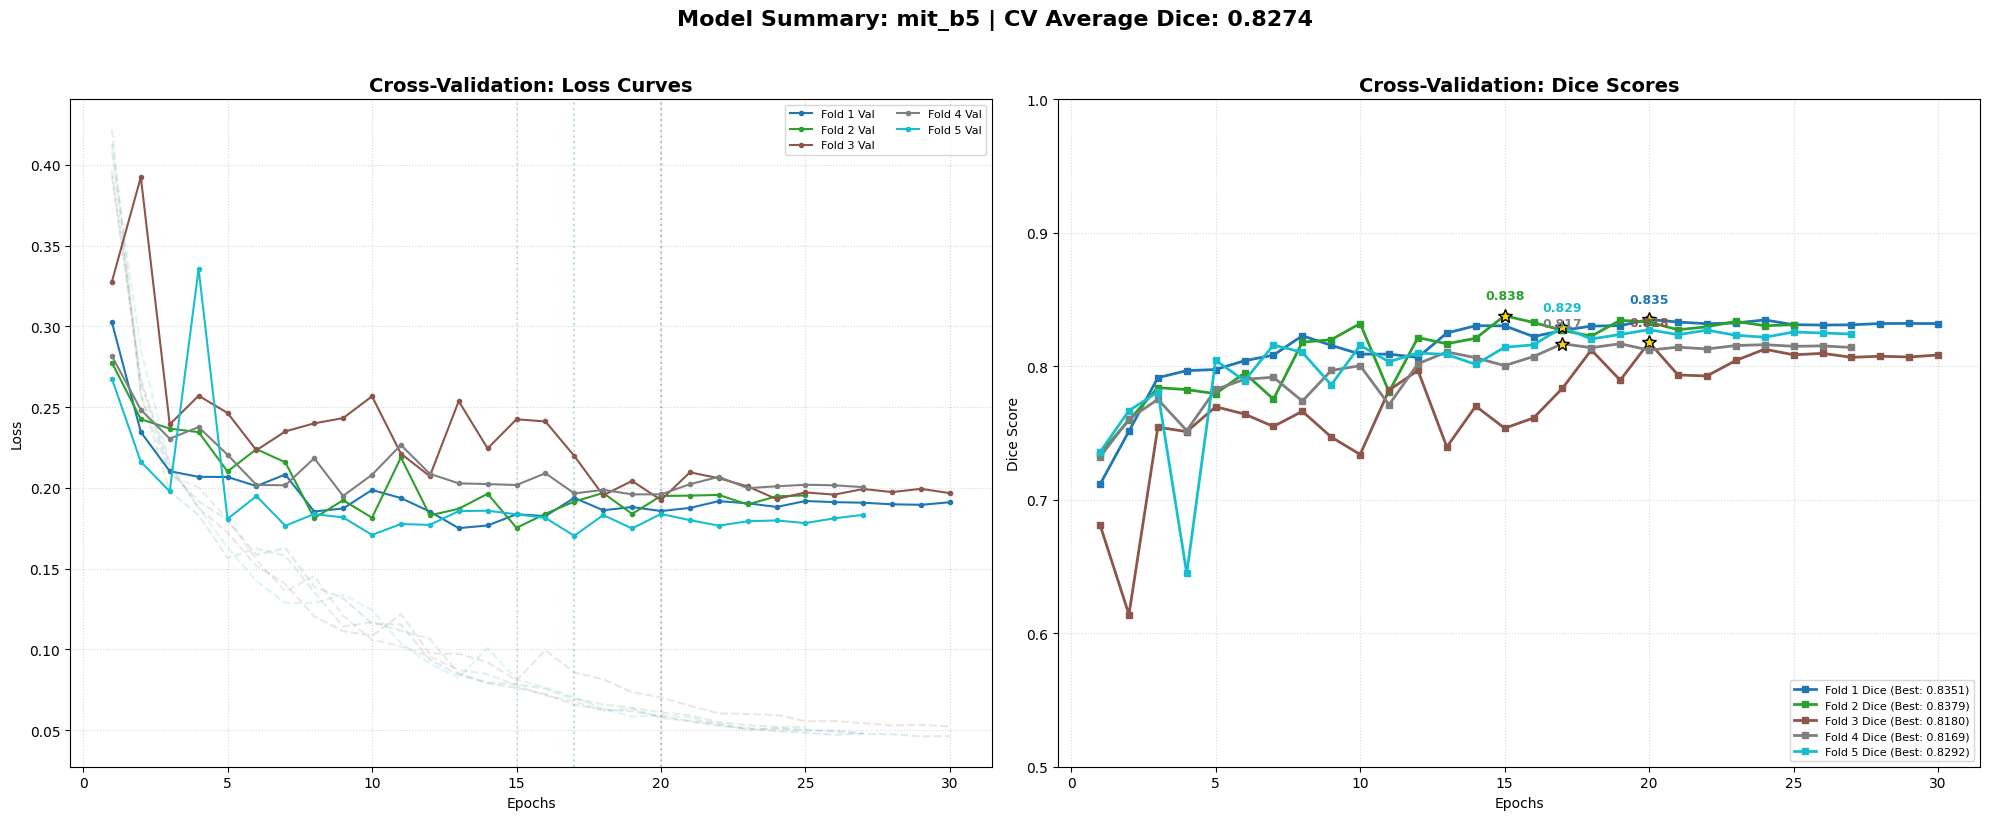

In [36]:
def plot_combined_curves(histories):
    if not histories:
        print("No history found. Make sure training has started.")
        return

    fig, axes = plt.subplots(1, 2, figsize=(20, 8))
    colors = plt.cm.tab10(np.linspace(0, 1, len(histories)))
    
    all_best_dice = []

    for i, h in enumerate(histories):
        epochs = range(1, len(h['val_loss']) + 1)
        best_dice = max(h['val_dice'])
        best_epoch = h['val_dice'].index(best_dice) + 1
        all_best_dice.append(best_dice)
        
        # --- Plot 1: Loss ---
        axes[0].plot(epochs, h['train_loss'], alpha=0.15, linestyle='--', color=colors[i]) 
        axes[0].plot(epochs, h['val_loss'], label=f'Fold {i+1} Val', color=colors[i], 
                     marker='o', markersize=3, linewidth=1.5)
        # Tambah vline di best epoch (berdasarkan Dice)
        axes[0].axvline(best_epoch, color=colors[i], alpha=0.2, linestyle=':')

        # --- Plot 2: Dice Score ---
        axes[1].plot(epochs, h['val_dice'], label=f'Fold {i+1} Dice (Best: {best_dice:.4f})', 
                     color=colors[i], marker='s', markersize=4, linewidth=2)
        
        # Tandai titik terbaik dengan bintang emas atau marker khusus
        axes[1].plot(best_epoch, best_dice, marker='*', color='gold', markersize=10, markeredgecolor='black')
        
        # Anotasi teks
        axes[1].annotate(f'{best_dice:.3f}', xy=(best_epoch, best_dice), 
                         textcoords="offset points", xytext=(0,12), ha='center', 
                         fontsize=9, color=colors[i], fontweight='bold')

    # Styling Grafik Loss
    axes[0].set_title('Cross-Validation: Loss Curves', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Epochs')
    axes[0].set_ylabel('Loss')
    axes[0].legend(loc='upper right', fontsize='8', ncol=2)
    axes[0].grid(True, linestyle=':', alpha=0.5)

    # Styling Grafik Dice
    axes[1].set_title('Cross-Validation: Dice Scores', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Epochs')
    axes[1].set_ylabel('Dice Score')
    axes[1].set_ylim(min(0.5, min([min(h['val_dice']) for h in histories])), 1.0) # Zoom otomatis tapi tetap ke arah 1.0
    axes[1].legend(loc='lower right', fontsize='8', ncol=1)
    axes[1].grid(True, linestyle=':', alpha=0.5)

    # Info Tambahan
    avg_dice = sum(all_best_dice) / len(all_best_dice)
    plt.suptitle(f"Model Summary: {CFG['encoder']} | CV Average Dice: {avg_dice:.4f}", 
                 fontsize=16, fontweight='bold', y=1.02)
    
    plt.tight_layout()
    plt.show()

# Panggil fungsi
plot_combined_curves(all_histories)

## 7. Inference
Average of the 5 fold models, each on the original and the horizontally flipped image. The averaged map is resized to the original size, thresholded at 0.5, cleaned (regions under 150 px removed, closing with a radius-3 disk) and RLE-encoded.

In [37]:
import os
import cv2
import numpy as np
import pandas as pd
import torch
from tqdm import tqdm
import skimage.morphology as morph

def post_process(mask, threshold=0.5):
    """
    Membersihkan hasil prediksi dari noise kecil.
    """
    # Mengubah probabilitas menjadi biner
    mask = (mask > threshold)
    # Menghapus objek yang terlalu kecil (noise)
    mask = morph.remove_small_objects(mask, min_size=150)
    # Menutup lubang-lubang kecil di dalam mask (Closing)
    mask = morph.binary_closing(mask, morph.disk(3))
    return mask.astype(np.uint8)

def rle_encode(mask):
    """
    Konversi mask ke format Run-Length Encoding (RLE).
    """
    pixels = mask.T.flatten()
    pixels = np.concatenate([[0], pixels, [0]])
    runs = np.where(pixels[1:] != pixels[:-1])[0] + 1
    runs[1::2] -= runs[::2]
    return ' '.join(str(x) for x in runs)

# 1. Load Semua Model dari Tiap Fold (Ensemble)
models = []
for f in range(CFG['n_folds']):
    path = f'best_model_fold{f}.pth'
    if os.path.exists(path):
        m = build_model(CFG['encoder'])
        # Menggunakan map_location agar aman jika pindah perangkat (CPU/GPU)
        m.load_state_dict(torch.load(path, map_location=CFG['device']))
        m.to(CFG['device'])
        m.eval()
        models.append(m)
        print(f"✅ Loaded: {path}")

# 2. Proses Inference
submission = []

# Pastikan test_imgs berisi path lengkap ke gambar
for img_path in tqdm(test_imgs, desc="Inference Ensemble"):
    img_name = os.path.basename(img_path)
    img_orig = cv2.imread(img_path)
    img_orig = cv2.cvtColor(img_orig, cv2.COLOR_BGR2RGB)
    h_orig, w_orig = img_orig.shape[:2]
    
    # Preprocess sesuai standar training
    # val_aug harus mencakup Resize ke img_size dan Normalize
    x = val_aug(image=img_orig)['image'].unsqueeze(0).to(CFG['device'])
    
    # Placeholder untuk akumulasi prediksi (Ensemble + TTA)
    # Gunakan float32 untuk presisi saat rata-rata
    final_pred = torch.zeros((1, 1, CFG['img_size'], CFG['img_size']), device=CFG['device'])
    
    with torch.no_grad():
        for m in models:
            # TTA: Original Image
            p1 = torch.sigmoid(m(x))
            
            # TTA: Horizontal Flip
            # dims=[3] mengacu pada lebar (Width) dalam tensor [B, C, H, W]
            p2 = torch.sigmoid(m(torch.flip(x, dims=[3])))
            p2 = torch.flip(p2, dims=[3]) # Balikkan kembali hasil prediksinya
            
            # Gabungkan TTA rata-rata ke total ensemble
            final_pred += (p1 + p2) / 2
    
    # Hitung rata-rata akhir dari semua model fold
    final_pred /= len(models)
    
    # Pindahkan ke CPU dan kembalikan ke ukuran asli gambar
    pred_cpu = final_pred[0, 0].cpu().numpy()
    mask_res = cv2.resize(pred_cpu, (w_orig, h_orig))
    
    # Post-processing (Denoising & Thresholding)
    processed_mask = post_process(mask_res, threshold=0.5)
    
    # Encode ke RLE
    rle = rle_encode(processed_mask)
    
    submission.append({
        'ImageId': img_name, 
        'rle': rle # Gunakan nama kolom sesuai aturan kompetisi (rle/EncodedPixels)
    })

✅ Loaded: best_model_fold0.pth
✅ Loaded: best_model_fold1.pth
✅ Loaded: best_model_fold2.pth
✅ Loaded: best_model_fold3.pth
✅ Loaded: best_model_fold4.pth


## 8. Visual check
Original image, raw probability map and overlay for the first test images. The output is cleared in this public copy because it shows competition images.

In [38]:
import matplotlib.pyplot as plt
import os

def visualize_predictions(test_imgs, models, n_samples=3):
    """
    Menampilkan perbandingan gambar asli, mask mentah, dan hasil akhir overlay.
    """
    # Ambil sampel secara acak atau berurutan
    samples = test_imgs[:n_samples]
    
    # Kita gunakan 3 kolom agar bisa melihat prosesnya: Original, Raw Mask, Final Overlay
    fig, axes = plt.subplots(n_samples, 3, figsize=(20, 6 * n_samples))
    
    for i, img_path in enumerate(samples):
        # 1. Load Gambar
        img_orig = cv2.imread(img_path)
        img_orig = cv2.cvtColor(img_orig, cv2.COLOR_BGR2RGB)
        h, w = img_orig.shape[:2]
        
        # 2. Inference Ensemble + TTA
        # Gunakan val_aug yang sama untuk standarisasi input
        x = val_aug(image=img_orig)['image'].unsqueeze(0).to(CFG['device'])
        final_pred = torch.zeros((1, 1, CFG['img_size'], CFG['img_size']), device=CFG['device'])
        
        with torch.no_grad():
            for m in models:
                p1 = torch.sigmoid(m(x))
                # TTA Flip Horizontal
                p2 = torch.sigmoid(m(torch.flip(x, dims=[3])))
                final_pred += (p1 + torch.flip(p2, dims=[3])) / 2
        
        final_pred /= len(models)
        
        # Resize ke dimensi asli
        mask_raw = cv2.resize(final_pred[0,0].cpu().numpy(), (w, h))
        
        # 3. Post-Processing
        processed_mask = post_process(mask_raw)
        
        # 4. Membuat Overlay Berwarna Merah
        overlay = img_orig.copy()
        # Warna merah terang untuk pothole
        overlay[processed_mask == 1] = [255, 0, 0] 
        # Campur dengan gambar asli (alpha blending)
        alpha = 0.4
        output_overlay = cv2.addWeighted(overlay, alpha, img_orig, 1 - alpha, 0)
        
        # 5. Plotting
        # Kolom 1: Gambar Asli
        axes[i, 0].imshow(img_orig)
        axes[i, 0].set_title(f"Original: {os.path.basename(img_path)}", fontsize=12)
        axes[i, 0].axis('off')
        
        # Kolom 2: Raw Mask (Probabilitas)
        # Menampilkan heatmap prediksi model sebelum di-threshold
        im2 = axes[i, 1].imshow(mask_raw, cmap='inferno')
        axes[i, 1].set_title("Model Confidence (Raw)", fontsize=12)
        axes[i, 1].axis('off')
        # Tambah colorbar kecil untuk melihat tingkat keyakinan model
        plt.colorbar(im2, ax=axes[i, 1], fraction=0.046, pad=0.04)
        
        # Kolom 3: Final Overlay
        axes[i, 2].imshow(output_overlay)
        axes[i, 2].set_title("Post-Processed Overlay", fontsize=12)
        axes[i, 2].axis('off')
        
    plt.tight_layout()
    plt.show()

# Pastikan list models sudah terisi sebelum memanggil
visualize_predictions(test_imgs, models, n_samples=3)

## 9. Submission file

In [39]:
# 3. Save to CSV
df_sub = pd.DataFrame(submission)
df_sub.to_csv('submission_mitb5_tta.csv', index=False)
print("\n🚀 Submission file saved: submission_mitb5_tta.csv")


🚀 Submission file saved: submission.csv
